# Cosmetic recall analysis: from a product to an official warning

## The problem we want to solve
A shopper or retailer needs to know whether a specific cosmetic product or batch is covered by an official recall, why the recall was issued and what action the notice recommends.

**Research question:** Can public recall records support accurate product matching and understandable safety guidance?

**Proposed outcome:** A product lookup that links to the original recall, shows its market and affected batches, and explains why the match was made. We will measure matching errors before considering a public tool.

This notebook starts Week 1 with data inspection and a feasibility study, including an independent catalogue and two simple text retrieval baselines. It does not train a semantic AI model. The French source describes recalls published for the French market. The UK files contain aggregate regulatory notifications, which are a different unit of measurement.

## How to use this notebook
Choose **Run > Run All Cells**. Read each explanation before its code. Original files remain in `data/raw`. Missing information stays missing. A missing alert is not evidence that a product is safe.

## 1. Set up our workspace
We use your installed Anaconda packages. `pandas` works with tables and `matplotlib` draws charts. Python's built in ZIP and XML tools read the small UK spreadsheets without installing an extra spreadsheet package.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import xml.etree.ElementTree as ET
import hashlib
import re
import textwrap

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data/raw/rappelconso-v2-gtin-espaces.csv').is_file():
    PROJECT_DIR = Path.home() / 'projects/yuvaintern'
DATA_DIR = PROJECT_DIR / 'data/raw'
FRANCE_FILE = DATA_DIR / 'rappelconso-v2-gtin-espaces.csv'
UK_FILES = {
    '2025-2026': DATA_DIR / 'psd-report-data-tables-2025-2026.ods',
    '2024-2025': DATA_DIR / 'psd-report-2024-2025-data-tables.ods',
}
for path in [FRANCE_FILE, *UK_FILES.values()]:
    if not path.is_file():
        raise FileNotFoundError(f'Missing source file: {path}')

plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
pd.set_option('display.max_colwidth', 110)
print('Workspace:', PROJECT_DIR.name)

Workspace: yuvaintern


## 2. Record our sources
The hashes identify the exact files used. If a future download changes, its hash changes too.

- [France: RappelConso dataset](https://www.data.gouv.fr/datasets/rappelconso-v2-rappels-de-produits). [Formats and update guidance](https://rappel.conso.gouv.fr/support/open-data).
- [UK: PSD reports and data tables](https://www.gov.uk/government/statistics/product-safety-database-annual-reports). [2025 to 2026 report and limitations](https://www.gov.uk/government/statistics/product-safety-database-annual-reports/product-safety-database-report-2025-to-2026).

The French file is a downloaded snapshot, not a live feed. Sections 15 to 22 measure overlap with an independent product catalogue and test simple retrieval methods.

In [2]:
source_inventory = pd.DataFrame([
    {'file': path.name, 'bytes': path.stat().st_size,
     'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    for path in [FRANCE_FILE, *UK_FILES.values()]
])
display(source_inventory)

,file,bytes,sha256
0,rappelconso-v2-gtin-espaces.csv,25098072,89387d1182b4cddc142e496f9f0ac5d70e64d4db3d92873431054069dc1eb700
1,psd-report-data-tables-2025-2026.ods,13567,3b9d79e8bb59f6da691df7c4d5042d829a9adaf972f4e765897b1ffa0ca877ea
2,psd-report-2024-2025-data-tables.ods,11592,093c2b2d0ecf40d943e793f785bf109ae11da3035ecf9cb230534f73430c71bc


## 3. Load the French file without changing its meaning
The file uses semicolons between columns. We read all values as text so barcodes and batch identifiers keep leading zeros. The export includes an invisible byte order mark in one column name; removing it changes the header only. Blank cells are kept as missing values. Literal text such as NA remains text. We do not silently skip malformed rows.

In [3]:
raw = pd.read_csv(FRANCE_FILE, sep=';', encoding='utf-8-sig', dtype='string',
                  keep_default_na=False, na_values=[''])
raw.columns = raw.columns.str.replace('\ufeff', '', regex=False).str.strip()
if raw.columns.duplicated().any():
    raise ValueError('Duplicate column names after header cleanup.')
required = {'id', 'numero_fiche', 'numero_version', 'date_publication',
            'sous_categorie_produit', 'marque_produit', 'modeles_ou_references',
            'identification_produits', 'risques_encourus', 'motif_rappel',
            'conduites_a_tenir_par_le_consommateur', 'lien_vers_la_fiche_rappel'}
missing_columns = required - set(raw.columns)
if missing_columns:
    raise ValueError(f'Required columns missing: {sorted(missing_columns)}')
print(f'Loaded {len(raw):,} rows and {raw.shape[1]} columns across all product categories.')
display(raw[['sous_categorie_produit', 'marque_produit', 'date_publication']].head())

Loaded 18,730 rows and 34 columns across all product categories.


,sous_categorie_produit,marque_produit,date_publication
0,produits sucrés,cokoc,2026-10-01T16:58:37+00:00
1,viandes,medina,2026-10-01T16:15:23+00:00
2,viandes,corico,2026-10-01T16:14:36+00:00
3,autres,singly,2026-10-01T16:08:40+00:00
4,fruits et légumes,saint eloi,2026-10-01T16:03:37+00:00


## 4. Select cosmetic notices
We use the explicit cosmetic subcategory. The wider hygiene and beauty category also contains other products, so it would change our scope. Case and whitespace are normalised only for comparisons. French source text is retained.

In [4]:
cosmetic_mask = raw['sous_categorie_produit'].str.strip().str.casefold().eq('cosmétiques').fillna(False)
selected = raw.loc[cosmetic_mask].copy()
if selected.empty:
    raise ValueError('No cosmetic notices found. Check the subcategory values.')
exact_duplicates = int(selected.duplicated().sum())
cosmetics = selected.drop_duplicates().copy()
if cosmetics['id'].isna().any() or cosmetics['numero_fiche'].isna().any():
    raise ValueError('A cosmetic notice is missing its record identifier.')
if cosmetics['id'].duplicated().any() or cosmetics['numero_fiche'].duplicated().any():
    raise ValueError('Repeated notice identifiers require version review before counting.')

selection_log = pd.DataFrame([
    {'step': 'All categories in source', 'rows': len(raw)},
    {'step': 'Cosmetic rows selected', 'rows': len(selected)},
    {'step': 'Exact duplicate cosmetic rows removed', 'rows': exact_duplicates},
    {'step': 'Distinct cosmetic notices retained', 'rows': len(cosmetics)},
])
assert len(selected) == len(cosmetics) + exact_duplicates
display(selection_log)

,step,rows
0,All categories in source,18730
1,Cosmetic rows selected,296
2,Exact duplicate cosmetic rows removed,0
3,Distinct cosmetic notices retained,296


## 5. What each field tells us
One retained row is a recall notice, not an injured person, sale, or necessarily one unique product. A notice can cover multiple barcodes or batches. Our counts describe this source, not the percentage of cosmetics on the market that are unsafe.

In [5]:
field_guide = pd.DataFrame([
    ('id', 'Record identifier', 'Count and link records without confusing names'),
    ('numero_fiche', 'Official notice reference', 'Trace a result to its notice'),
    ('numero_version', 'Notice version', 'Recognise updates in future downloads'),
    ('date_publication', 'Publication timestamp', 'Understand when the warning was published'),
    ('marque_produit', 'Brand', 'Help distinguish products with similar names'),
    ('modeles_ou_references', 'Product name or reference', 'Search and review product variants'),
    ('identification_produits', 'Combined barcode, lot and date information', 'Match identities and verify affected batches'),
    ('risques_encourus', 'Reported hazard labels', 'Summarise the reasons for safety concern'),
    ('motif_rappel', 'Reason for recall', 'Explain the notice using its evidence'),
    ('conduites_a_tenir_par_le_consommateur', 'Consumer instructions', 'Show the action provided in the source'),
    ('lien_vers_la_fiche_rappel', 'Official notice link', 'Let a reader check the original record'),
], columns=['source_field', 'plain_meaning', 'use'])
display(field_guide)

,source_field,plain_meaning,use
0,id,Record identifier,Count and link records without confusing names
1,numero_fiche,Official notice reference,Trace a result to its notice
2,numero_version,Notice version,Recognise updates in future downloads
3,date_publication,Publication timestamp,Understand when the warning was published
4,marque_produit,Brand,Help distinguish products with similar names
5,modeles_ou_references,Product name or reference,Search and review product variants
6,identification_produits,"Combined barcode, lot and date information",Match identities and verify affected batches
7,risques_encourus,Reported hazard labels,Summarise the reasons for safety concern
8,motif_rappel,Reason for recall,Explain the notice using its evidence
9,conduites_a_tenir_par_le_consommateur,Consumer instructions,Show the action provided in the source


## 6. Missing information: measure it before choosing a method
Whitespace-only fields count as missing. We retain notices with missing product names or instructions. An empty instruction must not become an invented recommendation. Missing percentages use retained cosmetic notices as the denominator.

In [6]:
fields = field_guide['source_field'].tolist()
present = cosmetics[fields].apply(lambda col: col.str.strip().replace('', pd.NA))
quality = pd.DataFrame({
    'missing_notices': present.isna().sum(),
    'missing_percent': present.isna().mean().mul(100).round(1),
    'available_notices': present.notna().sum(),
}).sort_values('missing_notices', ascending=False)
display(quality)
print('Cleaning policy: retain missing values; show source information unavailable in the lookup.')

,missing_notices,missing_percent,available_notices
conduites_a_tenir_par_le_consommateur,5,1.7,291
id,0,0.0,296
numero_fiche,0,0.0,296
numero_version,0,0.0,296
date_publication,0,0.0,296
marque_produit,0,0.0,296
modeles_ou_references,0,0.0,296
identification_produits,0,0.0,296
risques_encourus,0,0.0,296
motif_rappel,0,0.0,296


Cleaning policy: retain missing values; show source information unavailable in the lookup.


## 7. Publication dates and coverage
Publication dates are not the dates injuries happened. Parsing failures are flagged, retained in the data and excluded only from the time chart. We do not fill a missing date. The first and last years are partial snapshots.

Unusable publication dates: 0
First publication: 2021-04-20
Last publication: 2026-09-25


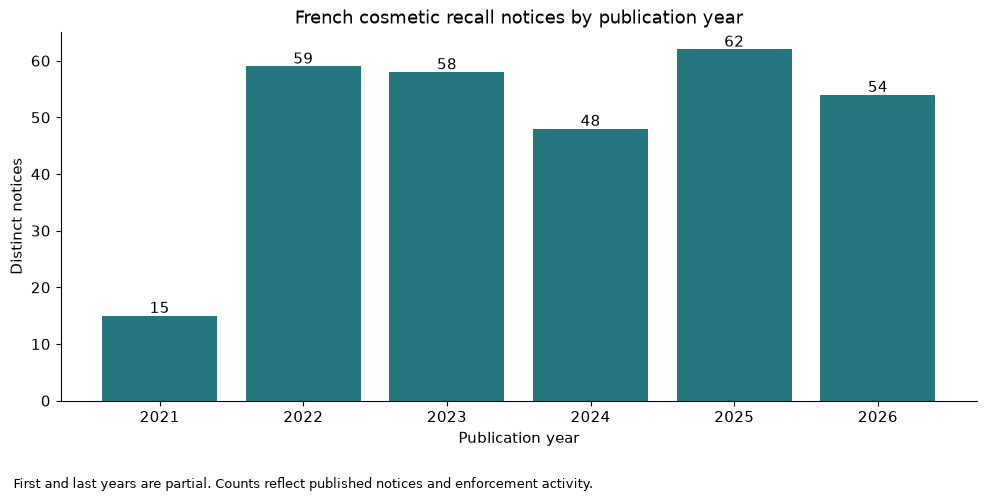

In [7]:
cosmetics['publication_date'] = pd.to_datetime(cosmetics['date_publication'], utc=True, errors='coerce')
invalid_dates = cosmetics['publication_date'].isna()
print('Unusable publication dates:', int(invalid_dates.sum()))
if invalid_dates.any():
    display(cosmetics.loc[invalid_dates, ['id', 'date_publication']])
valid_dates = cosmetics.loc[~invalid_dates, 'publication_date']
if valid_dates.empty:
    raise ValueError('No valid publication dates to analyse.')
print('First publication:', valid_dates.min().date())
print('Last publication:', valid_dates.max().date())

year_counts = valid_dates.dt.year.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(year_counts.index.astype(str), year_counts.values, color='#267680')
for i, count in enumerate(year_counts.values):
    ax.text(i, count + 0.5, str(count), ha='center')
ax.set(title='French cosmetic recall notices by publication year',
       xlabel='Publication year', ylabel='Distinct notices')
fig.text(0.02, 0.01, 'First and last years are partial. Counts reflect published notices and enforcement activity.', fontsize=9)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 8. What hazards appear in the notices?
A notice can list several hazards separated by `|`. We split these labels and count each notice once for each label. Therefore, the bars can add up to more than the total number of notices. These are source hazard labels, not counts of confirmed injuries. English labels below are a small explicit glossary; other labels remain in French.

,source_label,notices,share_of_notices_percent
0,risque chimique,98,33.1
1,blessures,60,20.3
2,dommages internes,40,13.5
3,risque microbiologique,39,13.2
4,intoxication,37,12.5
5,risque environnemental,14,4.7
6,autres contaminants biologiques,5,1.7
7,brûlures,4,1.4
8,substances allergisantes non déclarées,4,1.4
9,arrêt respiratoire,4,1.4


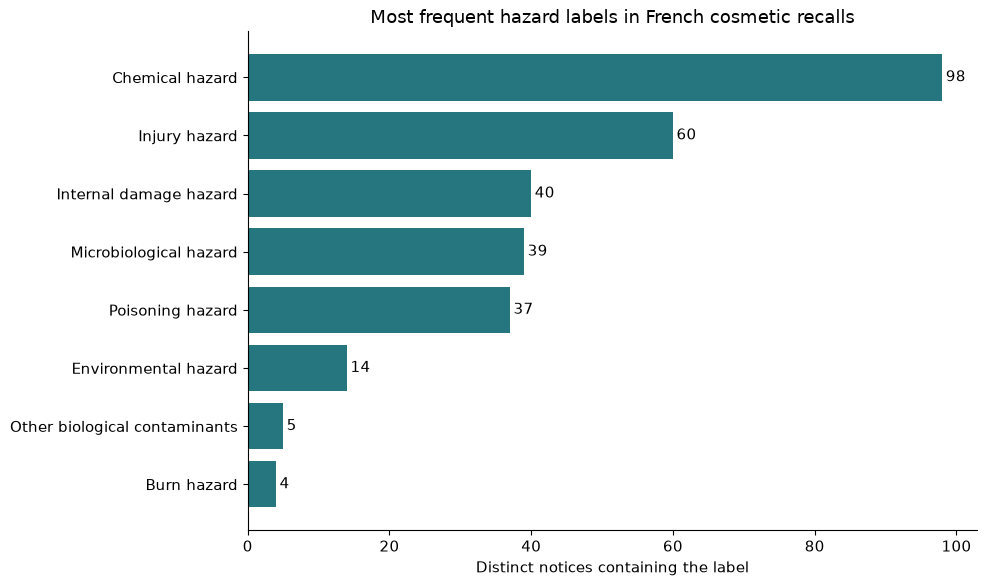

In [8]:
hazard_glossary = {
    'risque chimique': 'Chemical hazard', 'blessures': 'Injury hazard',
    'dommages internes': 'Internal damage hazard', 'risque microbiologique': 'Microbiological hazard',
    'intoxication': 'Poisoning hazard', 'risque environnemental': 'Environmental hazard',
    'autres contaminants biologiques': 'Other biological contaminants',
    'arrêt respiratoire': 'Respiratory arrest hazard',
    'substances allergisantes non déclarées': 'Undeclared allergenic substances',
    'brûlures': 'Burn hazard', 'présence de substance interdite': 'Prohibited substance',
}
hazards = cosmetics[['id', 'risques_encourus']].copy()
hazards['hazard'] = hazards['risques_encourus'].str.split('|', regex=False)
hazards = hazards.explode('hazard')
hazards['hazard'] = hazards['hazard'].str.strip().replace('', pd.NA)
hazards = hazards.dropna(subset=['hazard']).drop_duplicates(['id', 'hazard'])
hazard_counts = hazards['hazard'].value_counts()
hazard_summary = hazard_counts.rename_axis('source_label').reset_index(name='notices')
hazard_summary['share_of_notices_percent'] = (hazard_summary['notices'] / len(cosmetics) * 100).round(1)
display(hazard_summary)
top_hazards = hazard_counts.head(8).sort_values()
labels = [textwrap.fill(hazard_glossary[label] if label in hazard_glossary else label, 35) for label in top_hazards.index]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, top_hazards.values, color='#267680')
for i, count in enumerate(top_hazards.values):
    ax.text(count + 0.5, i, str(count), va='center')
ax.set(title='Most frequent hazard labels in French cosmetic recalls', xlabel='Distinct notices containing the label')
fig.tight_layout()
plt.show()

## 9. Can the identifiers support product lookup?
The downloaded file combines barcodes and lots into one field. We inspect the first comma-separated item of each `|`-separated entry. We accept only a single all-digit GTIN of length 8, 12, 13 or 14 with a valid check digit. Unusual identifiers remain available for manual review. This conservative method can miss usable identifiers; it avoids silently guessing them.

GTIN is the standard barcode identifier. Its final digit checks for common typing errors. Valid identifiers are padded to 14 digits for equivalent comparisons. A valid check digit does not prove the product is authentic. The original combined field remains the authority for batches.

In [9]:
def valid_gtin(value):
    if not re.fullmatch(r'(?:[0-9]{8}|[0-9]{12}|[0-9]{13}|[0-9]{14})', value):
        return False
    total = sum(int(digit) * (3 if i % 2 == 0 else 1)
                for i, digit in enumerate(reversed(value[:-1])))
    return (10 - total % 10) % 10 == int(value[-1])

assert valid_gtin('4006381333931')
assert not valid_gtin('4006381333932')
assert not valid_gtin('all lots')

identifier_rows = []
for notice_id, field in cosmetics[['id', 'identification_produits']].itertuples(index=False, name=None):
    if pd.isna(field):
        continue
    for entry in field.split('|'):
        candidate = entry.partition(',')[0].strip()
        valid = valid_gtin(candidate)
        identifier_rows.append({'id': notice_id, 'candidate': candidate,
                                'valid_gtin': valid,
                                'gtin14': candidate.zfill(14) if valid else pd.NA,
                                'source_entry': entry.strip()})
identifiers = pd.DataFrame(identifier_rows, columns=['id', 'candidate', 'valid_gtin', 'gtin14', 'source_entry'])
barcode_index = identifiers.loc[identifiers['valid_gtin'], ['id', 'gtin14']].drop_duplicates()
matched_ids = set(barcode_index['id'])
barcode_coverage = len(matched_ids) / len(cosmetics) * 100
print(f'{len(matched_ids)} of {len(cosmetics)} notices ({barcode_coverage:.1f}%) contain at least one accepted GTIN.')
print('Distinct accepted GTINs:', barcode_index['gtin14'].nunique())
print('Entries requiring review:', int((~identifiers['valid_gtin']).sum()))
display(identifiers.loc[~identifiers['valid_gtin'], ['id', 'candidate', 'source_entry']].head(10))
print('Next check: compare parsed GTINs with the original notice before claiming matching accuracy.')

197 of 296 notices (66.6%) contain at least one accepted GTIN.
Distinct accepted GTINs: 308
Entries requiring review: 125


,id,candidate,source_entry
2,23536,68918047159,"68918047159,tous les lots,non concerné"
8,23337,tous les lots,"tous les lots,non concerné"
11,23121,601102068371738,"601102068371738,20250620,date limite de consommation,2028-06-19"
18,22563,23456789,"23456789,tous les lots,date limite de consommation,2026-06-15"
20,22557,tous les lots,"tous les lots,non concerné"
29,49579,code rappel: 8436037793370,code rappel: 8436037793370
40,22146,377003622106,"377003622106,tous les lots,non concerné"
48,21844,34043,"34043,non concerné"
58,49852,code rappel: 7908024951038,code rappel: 7908024951038
59,49647,code rappel: 8683581057438,code rappel: 8683581057438


Next check: compare parsed GTINs with the original notice before claiming matching accuracy.


## 10. Try a first barcode lookup
The example below uses a barcode from a recall record. It demonstrates retrieval, not independent validation. Replace `QUERY_BARCODE` with your own barcode and rerun this cell. A product can have several recall notices. The output shows every matching notice and retains the original batch information and French instructions.

An identifier match is a candidate alert. Verify the variant, affected lot and jurisdiction in the official notice. An unknown batch cannot be treated as an unaffected batch.

In [10]:
def lookup_barcode(query):
    value = str(query).strip()
    if not valid_gtin(value):
        raise ValueError('Enter a valid 8, 12, 13 or 14 digit GTIN. Keep leading zeros.')
    notice_ids = barcode_index.loc[barcode_index['gtin14'].eq(value.zfill(14)), 'id']
    result = cosmetics.loc[cosmetics['id'].isin(notice_ids), [
        'numero_fiche', 'marque_produit', 'modeles_ou_references', 'identification_produits',
        'risques_encourus', 'motif_rappel', 'conduites_a_tenir_par_le_consommateur',
        'lien_vers_la_fiche_rappel', 'date_publication',
    ]].copy()
    return result.rename(columns={
        'numero_fiche': 'notice_reference', 'marque_produit': 'brand',
        'modeles_ou_references': 'product', 'identification_produits': 'original_barcode_and_batch_details',
        'risques_encourus': 'hazards_in_source', 'motif_rappel': 'reason_in_source',
        'conduites_a_tenir_par_le_consommateur': 'instructions_in_source',
        'lien_vers_la_fiche_rappel': 'official_notice', 'date_publication': 'published',
    })

if barcode_index.empty:
    raise ValueError('No accepted GTIN available for the lookup demonstration.')
QUERY_BARCODE = barcode_index.iloc[0]['gtin14']
matches = lookup_barcode(QUERY_BARCODE)
print('Example GTIN:', QUERY_BARCODE)
print('Market: France. Verify the affected lot in the official notice.')
if matches.empty:
    print('No matching notice in this snapshot. This does not establish product safety.')
else:
    display(matches.fillna('Not provided in the source').T)

Example GTIN: 06130024168258
Market: France. Verify the affected lot in the official notice.


,48
notice_reference,2026-09-0240
brand,venus
product,3en1 family shampoo à la kératine à l'extrait d'ail – flacon 1 l
original_barcode_and_batch_details,"6130024168258,03/2029/lot28/s20,non concerné"
hazards_in_source,risque chimique
reason_in_source,prélèvement dgccrf du 21/07/2026 chez perlla distrib¤analyse service commun des laboratoires dgccrf-dgddi ...
instructions_in_source,ne plus consommer|rapporter le produit au point de vente
official_notice,https://rappel.conso.gouv.fr/fiche-rappel/23621/interne
published,2026-09-25T12:42:18+00:00


## 11. Read the UK spreadsheets as supporting context
An ODS spreadsheet is a ZIP file containing XML tables. We read the stored text and preserve repeated cells so column positions are correct. Empty trailing cells are removed. These files contain summary counts, not individual product barcodes or batches.

We display the category tables for both years separately. The 2025 to 2026 release changed category definitions, and authorities do not use the database consistently. A difference between these years must not be described as a measured increase in unsafe cosmetics.

In [11]:
ODS_NS = {'table': 'urn:oasis:names:tc:opendocument:xmlns:table:1.0',
          'text': 'urn:oasis:names:tc:opendocument:xmlns:text:1.0'}

def read_ods_sheet(path, sheet_name):
    with ZipFile(path) as archive:
        document = ET.fromstring(archive.read('content.xml'))
    tables = document.findall('.//table:table', ODS_NS)
    matches = [table for table in tables
               if table.attrib['{' + ODS_NS['table'] + '}name'] == sheet_name]
    if len(matches) != 1:
        raise ValueError(f'Expected exactly one sheet named {sheet_name} in {path.name}')
    rows = []
    for row in matches[0].findall('table:table-row', ODS_NS):
        entries = []
        for cell in row:
            if cell.tag not in ['{' + ODS_NS['table'] + '}table-cell',
                                '{' + ODS_NS['table'] + '}covered-table-cell']:
                continue
            value = ' '.join(''.join(p.itertext()) for p in cell.findall('text:p', ODS_NS))
            repeat = int(cell.attrib.get('{' + ODS_NS['table'] + '}number-columns-repeated', '1'))
            entries.append((value, repeat))
        while entries and entries[-1][0] == '':
            entries.pop()
        cells = []
        for value, repeat in entries:
            if repeat < 1 or len(cells) + repeat > 1024:
                raise ValueError('Unexpected populated ODS width. Review this sheet before import.')
            cells.extend([value] * repeat)
        if cells:
            repeat = int(row.attrib.get('{' + ODS_NS['table'] + '}number-rows-repeated', '1'))
            if repeat < 1 or repeat > 1024:
                raise ValueError('Unexpected ODS row repetition.')
            rows.extend([cells.copy() for _ in range(repeat)])
    if not rows:
        raise ValueError('Empty ODS sheet.')
    return rows

uk_categories = {}
for period, path in UK_FILES.items():
    rows = read_ods_sheet(path, 'Table_02')
    headers = [i for i, row in enumerate(rows) if row[:3] == ['Category', 'Number', 'Percentage (%)']]
    if len(headers) != 1:
        raise ValueError(f'Unexpected category table headers: {path.name}')
    start = headers[0]
    table = pd.DataFrame([row[:3] for row in rows[start + 1:] if len(row) >= 3],
                         columns=['category', 'notified_products', 'source_percentage'])
    table['notified_products'] = pd.to_numeric(table['notified_products'], errors='raise')
    table['source_percentage'] = pd.to_numeric(table['source_percentage'], errors='raise')
    totals = table.loc[table['category'].str.casefold().eq('total'), 'notified_products']
    if len(totals) != 1:
        raise ValueError('Expected one source total in the UK category table.')
    assert table.loc[~table['category'].str.casefold().eq('total'), 'notified_products'].sum() == totals.iloc[0], 'UK categories do not reconcile to the source total.'
    uk_categories[period] = table
    print(f'UK {period}: category counts across all product sectors')
    display(table.head(10))
    print('Beauty-related row:')
    display(table.loc[table['category'].str.contains('cosmetic', case=False, regex=False)])

UK 2025-2026: category counts across all product sectors


,category,notified_products,source_percentage
0,"Cosmetics, personal care and grooming",833,25
1,Toys,732,22
2,Electrical appliances and equipment,545,16
3,Hobby/sports equipment,178,5
4,Childcare articles and children's equipment,163,5
5,Machinery,134,4
6,Lighting equipment,122,4
7,Personal protective equipment (PPE),67,2
8,Hand tools/accessories,66,2
9,Motor vehicles (including spare parts),61,2


Beauty-related row:


,category,notified_products,source_percentage
0,"Cosmetics, personal care and grooming",833,25


UK 2024-2025: category counts across all product sectors


,category,notified_products,source_percentage
0,Electrical appliances and equipment,470,26
1,Toys,344,19
2,Cosmetics,213,12
3,Childcare articles and children's equipment,159,9
4,Machinery,106,6
5,"Clothing, textiles and fashion items",87,5
6,Personal protective equipment (PPE),67,4
7,Jewellery,60,3
8,Hand tools,48,3
9,Decorative articles,34,2


Beauty-related row:


,category,notified_products,source_percentage
2,Cosmetics,213,12


## 12. What the UK numbers can and cannot tell us
The chart uses one year only and its original category names. Counts are notified products, which include unsafe or non-compliant products. They are not counts of people harmed or necessarily counts of recalls. Some products can appear in more than one notification.

The UK aggregate tables are not joined to French notices. Country, reporting period, measurement unit and enforcement process differ. UK hazard totals across all sectors cannot be attributed to cosmetics.

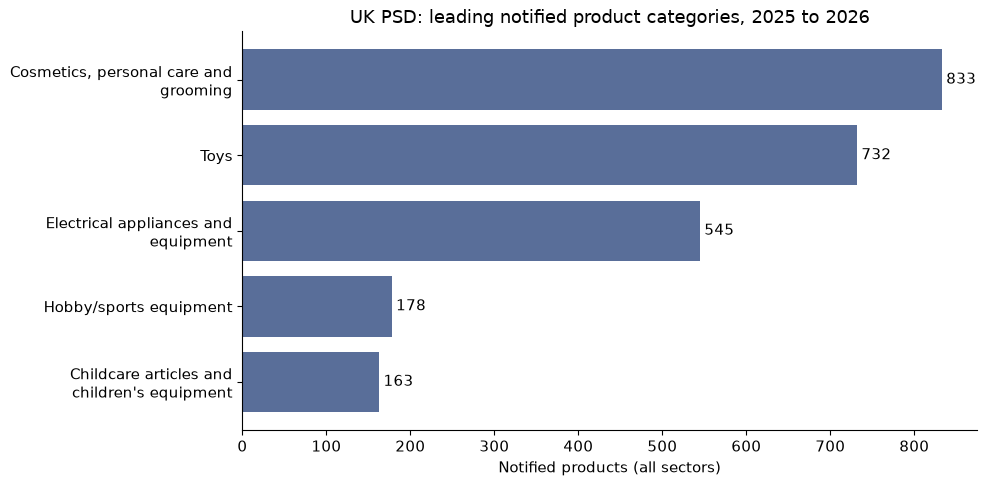

In [12]:
uk_latest = uk_categories['2025-2026']
top_uk = uk_latest.loc[~uk_latest['category'].str.casefold().isin(['total', 'all other categories'])].head(5).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
labels = [textwrap.fill(value, 28) for value in top_uk['category']]
ax.barh(labels, top_uk['notified_products'], color='#596e99')
for i, count in enumerate(top_uk['notified_products']):
    ax.text(count + 5, i, str(count), va='center')
ax.set(title='UK PSD: leading notified product categories, 2025 to 2026',
       xlabel='Notified products (all sectors)')
fig.tight_layout()
plt.show()

## 13. Preliminary findings from these files
These observations describe our downloaded records. They are not model performance results or measured reductions in harm. The data quality counts below are computed, so they update if the source changes.

In [13]:
uk_beauty = uk_latest.loc[uk_latest['category'].str.contains('cosmetic', case=False, regex=False)]
if len(uk_beauty) != 1:
    raise ValueError('Expected one UK cosmetics-related category row.')
leading_hazard = hazard_counts.index[0]
leading_count = int(hazard_counts.iloc[0])
missing_instructions = int(quality.loc['conduites_a_tenir_par_le_consommateur', 'missing_notices'])
display(Markdown(f"""
- **France:** {len(cosmetics):,} distinct cosmetic recall notices, published from {valid_dates.min().date()} to {valid_dates.max().date()}.
- **Recurring concern:** `{leading_hazard}` appears in {leading_count} notices ({leading_count / len(cosmetics):.1%} of our retained notices). This is a hazard-label count, not a harm rate.
- **Lookup feasibility:** {barcode_coverage:.1f}% of notices contain at least one GTIN accepted by our conservative parser. Parsed identities still need checking against original notices.
- **Information gap:** {missing_instructions} notices lack consumer instructions in the exported field. A tool must link to the source rather than invent missing guidance.
- **UK context:** {int(uk_beauty.iloc[0]['notified_products']):,} notified products are in `{uk_beauty.iloc[0]['category']}` ({uk_beauty.iloc[0]['source_percentage']:g}% using the source's rounded percentage).
"""))


- **France:** 296 distinct cosmetic recall notices, published from 2021-04-20 to 2026-09-25.
- **Recurring concern:** `risque chimique` appears in 98 notices (33.1% of our retained notices). This is a hazard-label count, not a harm rate.
- **Lookup feasibility:** 66.6% of notices contain at least one GTIN accepted by our conservative parser. Parsed identities still need checking against original notices.
- **Information gap:** 5 notices lack consumer instructions in the exported field. A tool must link to the source rather than invent missing guidance.
- **UK context:** 833 notified products are in `Cosmetics, personal care and grooming` (25% using the source's rounded percentage).


## 14. Feasibility study: is this worth our six weeks?

Think of a recall like a letter addressed to a particular bottle, sometimes only to bottles from one manufacturing batch. Matching the brand is like finding the right street. Matching the barcode finds the house. Checking the batch finds the intended person.

**Refined problem:** Help a consumer or retailer identify which published French cosmetic recall might apply to their product, preserve the affected batch conditions, and explain the official next step with traceable evidence.

**Potential benefit:** Fewer missed relevant notices and fewer unnecessary warnings, with less time spent checking a product. These are outcomes to test, not benefits we have already measured. The data cannot establish injuries prevented.

**Why the need is current:** Cosmetics accounted for 36% of Safety Gate alerts in 2025. That is the share of alerts, not the share of unsafe products on sale. The report also describes an existing online surveillance system, so finding recalled products online is already an active regulatory task. [European Commission report](https://op.europa.eu/webpub/just/safety-gate-2025-report/en/).

**What already exists:** RappelConso publishes official warnings. Alerte-Conso describes barcode scanning, stored lots, photos and alerts. Its page is a developer description, not an independent performance evaluation. A scanner alone is therefore insufficient novelty. Our contribution should be a transparent matching benchmark and error analysis, with any improvement demonstrated against simple methods. [Existing application](https://www.data.gouv.fr/reuses/alerte-conso-rappels-de-produits-scan-et-suivi).

We will check catalogue overlap, text retrieval errors and batch ambiguity before selecting an AI model. This is a historical French feasibility study. Real-time operation and Indian deployment are later questions requiring fresh feeds, local records and product checks.

## 15. An independent product catalogue, downloaded automatically

[Open Beauty Facts](https://www.data.gouv.fr/datasets/open-beauty-facts) contains citizen-contributed product identities, labels and ingredients. It is independent of our recall export, but its records are not certified manufacturer truth. A matching barcode is a provisional identity label, not confirmation that a particular batch is recalled.

The publisher documents public bulk export access in its [download FAQ](https://support.openfoodfacts.org/help/en-gb/11-open-beauty-facts/70-where-can-i-download-open-beauty-facts-data). We obtained the gzip CSV from [publisher's compressed export](https://static.openbeautyfacts.org/data/en.openbeautyfacts.org.products.csv.gz) and verified its compression checksum. The notebook uses the saved file and makes no network requests when rerun. Download metadata includes the source URL, retrieval time, HTTP headers, byte count and hash. A partial download must never be analysed as a complete snapshot.

The catalogue uses ODbL with attribution and share-alike conditions. Keep source attribution and review the combined-data licence before publishing a joined dataset. [Publisher's reuse guidance](https://support.openfoodfacts.org/help/en-gb/12-donnees-api/94-y-a-t-il-des-conditions-pour-utiliser-l-api). Raw catalogue data is excluded from Git.

We read only product fields needed for this question. Fields such as nutrition are irrelevant to cosmetics even if present in the export schema. Product names and ingredients can be absent. We do not fill them with invented values.

In [14]:
import json
import unicodedata
from sklearn.feature_extraction.text import TfidfVectorizer

CATALOGUE_FILE = DATA_DIR / 'openbeautyfacts-products.tsv'
METADATA_FILE = DATA_DIR / 'openbeautyfacts-download.json'
catalogue_metadata = json.loads(METADATA_FILE.read_text())
if catalogue_metadata['complete'] is not True:
    raise ValueError('Catalogue download was not completed successfully.')
if catalogue_metadata['bytes'] != CATALOGUE_FILE.stat().st_size:
    raise ValueError('Catalogue size differs from the download record.')
catalogue_hash = hashlib.sha256(CATALOGUE_FILE.read_bytes()).hexdigest()
if catalogue_hash != catalogue_metadata['sha256']:
    raise ValueError('Catalogue hash differs from the download record.')

catalogue_fields = ['code', 'url', 'product_name', 'brands', 'quantity',
                    'countries_tags', 'ingredients_text', 'last_modified_datetime']
catalogue_raw = pd.read_csv(CATALOGUE_FILE, sep='\t', dtype='string',
                          keep_default_na=False, na_values=[''],
                          usecols=catalogue_fields)
catalogue_valid = catalogue_raw['code'].fillna('').map(valid_gtin)
catalogue = catalogue_raw.loc[catalogue_valid].copy()
catalogue['gtin14'] = catalogue['code'].str.zfill(14)
if catalogue['gtin14'].duplicated().any():
    raise ValueError('Repeated catalogue GTINs require review before joining.')
catalogue['has_name'] = catalogue['product_name'].fillna('').str.strip().ne('')
catalogue['has_brand'] = catalogue['brands'].fillna('').str.strip().ne('')
catalogue['has_ingredients'] = catalogue['ingredients_text'].fillna('').str.strip().ne('')
display(pd.DataFrame([
    ('Raw catalogue records', len(catalogue_raw)),
    ('Records with accepted GTIN', len(catalogue)),
    ('Excluded from barcode join: invalid or missing GTIN', int((~catalogue_valid).sum())),
    ('Accepted identities with product name', int(catalogue['has_name'].sum())),
    ('Accepted identities with brand', int(catalogue['has_brand'].sum())),
    ('Accepted identities with ingredients', int(catalogue['has_ingredients'].sum())),
], columns=['quality_check', 'records']))
display(pd.DataFrame([catalogue_metadata]).drop(columns=['response_headers']))
assert len(catalogue_raw) == len(catalogue) + int((~catalogue_valid).sum())

,quality_check,records
0,Raw catalogue records,64237
1,Records with accepted GTIN,62505
2,Excluded from barcode join: invalid or missing GTIN,1732
3,Accepted identities with product name,39017
4,Accepted identities with brand,33738
5,Accepted identities with ingredients,17243


,source,source_url,documentation,retrieved_utc,complete,http_status,compression_verified,bytes,sha256,compressed_bytes,compressed_sha256,licence
0,Open Beauty Facts,https://static.openbeautyfacts.org/data/en.openbeautyfacts.org.products.csv.gz,https://support.openfoodfacts.org/help/en-gb/11-open-beauty-facts/70-where-can-i-download-open-beauty-fact...,2026-10-02T07:39:26.750093+00:00,True,200,gzip CRC and length verified by reading to EOF,167614987,a47ffee532c3b5a2e81944af4f2d2145e4c20d86d5f288c4f9a00d65467fc2c1,17884435,d527f033d2549b86424db0ef1e87b785f92f53901036afd0c0a24bd629a766a5,ODbL-1.0


## 16. How much overlap do we really have?

We join canonical GTINs, not similar product names. A notice can cover multiple products, so we report both unique products and unique notices. This is catalogue coverage within our recall snapshot, not recall accuracy across the whole market.

The table lets us inspect independently written names side by side. Inconsistent naming or catalogue mistakes must be reviewed before using a join as a trusted label. Products absent from either file are **unobserved**, not safe.

Independent catalogue identities joined: 30
Recall notices represented: 22 of 296
Overlapping identities with a usable catalogue name: 17


,code,product_name,brands,marque_produit,modeles_ou_references,numero_fiche
0,6130024168258,<NA>,<NA>,venus,3en1 family shampoo à la kératine à l'extrait d'ail – flacon 1 l,2026-09-0240
1,8715658999027,Merta,Eau de parfum,merta,express sensualité captive,2026-08-0253
2,3327520004026,ACTICURL HYDRA SHAMPOOING ACTIVATEUR DE BOUCLES,ACTIVILONG,activilong acticurl,shampoing activateur de boucles 250ml activilong / acticurl lot 37019,2026-08-0072
3,3256229526778,Gel douche,U,u,gel douche mangue & passion by u 250ml,2026-05-0078
4,3326100000557,Pâte argile verte,Argiletz,argiletz,référence produit : 0024,2026-01-0130
5,3256226758066,demaquillant yeux bio marque U,U,u bio,démaquillant yeux express bleuet u bio flacon 150ml,2025-11-0028
6,3560071324988,<NA>,Carrefour,carrefour soft,a l'extrait de fleurs de camomille,2025-07-0012
7,3760209542301,Crème solaire 30,ParaSol,parasol,"spray sensitive 30, spray sensitive 50, spray 30 protection&bronzage, spray 50 protection&bronzage, lait 5...",2025-04-0306
8,3760209542516,<NA>,Laboratoire dermosun,parasol,"spray sensitive 30, spray sensitive 50, spray 30 protection&bronzage, spray 50 protection&bronzage, lait 5...",2025-04-0306
9,3760209542332,spray bronzant protecteur,parasol,parasol,"spray sensitive 30, spray sensitive 50, spray 30 protection&bronzage, spray 50 protection&bronzage, lait 5...",2025-04-0306


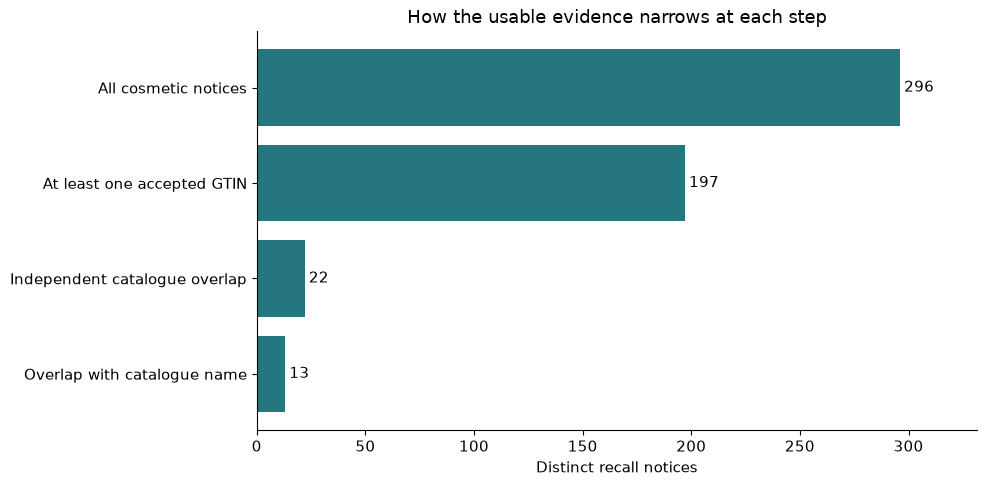

In [15]:
overlap = barcode_index.merge(catalogue, on='gtin14', how='inner', validate='many_to_one')
overlap = overlap.merge(cosmetics[['id', 'numero_fiche', 'marque_produit',
                                 'modeles_ou_references']],
                        on='id', validate='many_to_one')
overlap_products = overlap['gtin14'].nunique()
overlap_notices = overlap['id'].nunique()
named_overlap = overlap.loc[overlap['has_name']].copy()
print('Independent catalogue identities joined:', overlap_products)
print('Recall notices represented:', overlap_notices, 'of', len(cosmetics))
print('Overlapping identities with a usable catalogue name:', named_overlap['gtin14'].nunique())
display(overlap[['code', 'product_name', 'brands', 'marque_produit',
                 'modeles_ou_references', 'numero_fiche']].head(12))

coverage_stages = pd.Series({
    'All cosmetic notices': len(cosmetics),
    'At least one accepted GTIN': len(matched_ids),
    'Independent catalogue overlap': overlap_notices,
    'Overlap with catalogue name': named_overlap['id'].nunique(),
})
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(coverage_stages.index[::-1], coverage_stages.values[::-1], color='#267680')
for y, value in enumerate(coverage_stages.values[::-1]):
    ax.text(value + 2, y, str(value), va='center')
ax.set(xlabel='Distinct recall notices', title='How the usable evidence narrows at each step')
ax.set_xlim(0, len(cosmetics) * 1.12)
fig.tight_layout()
plt.show()

## 17. Where product identification becomes difficult

Not accepted does not mean missing. An identifier may be a short reference, a malformed GTIN, a labelled barcode or several values in one field. We show these separately. Embedded valid tokens are review candidates only; we do not silently promote them to verified identities.

For batch text we inspect the second comma-separated field only when the first field is an accepted GTIN. Labels below describe text shape. They do not certify that a batch can be matched safely. Dates, additional information and conditions outside this field can still matter.

In [16]:
def identifier_issue(value):
    if valid_gtin(value):
        return 'Accepted single GTIN'
    if value.isdigit():
        return 'Wrong check digit' if len(value) in (8, 12, 13, 14) else 'Non-standard numeric length'
    tokens = re.findall(r'(?<![0-9])[0-9]{8,14}(?![0-9])', value)
    if any(valid_gtin(token) for token in tokens):
        return 'Embedded valid token: needs source review'
    return 'Other text or reference: needs source review'

identifiers['parse_reason'] = identifiers['candidate'].map(identifier_issue)
display(identifiers.groupby('parse_reason').agg(
    entries=('id', 'size'), distinct_notices=('id', 'nunique')).sort_values('entries', ascending=False))
display(identifiers.loc[~identifiers['valid_gtin'],
                        ['id', 'candidate', 'parse_reason']].head(15))

def batch_shape(entry):
    fields = [field.strip() for field in entry.split(',')]
    if len(fields) < 3 or not valid_gtin(fields[0]):
        return 'Not reliably separated'
    batch = fields[1]
    if batch.casefold() in ('', 'non concerné', 'non concerne'):
        return 'No usable lot in second field'
    if batch.casefold() == 'tous les lots':
        return 'All lots stated'
    if re.fullmatch(r'[A-Za-z0-9]+(?:[-_][A-Za-z0-9]+)*', batch):
        return 'Single simple lot token'
    return 'Complex lot wording: manual review'

identifiers['batch_shape'] = identifiers['source_entry'].map(batch_shape)
batch_summary = identifiers.groupby('batch_shape').agg(
    entries=('id', 'size'), distinct_notices=('id', 'nunique')).sort_values('entries', ascending=False)
display(batch_summary)
print('A notice can appear in several groups; group counts must not be added as distinct notices.')
multiple_notices = barcode_index.groupby('gtin14')['id'].nunique()
print('GTINs appearing in more than one notice:', int(multiple_notices.gt(1).sum()))
display(barcode_index.loc[barcode_index['gtin14'].isin(multiple_notices[multiple_notices.gt(1)].index)]
        .merge(cosmetics[['id', 'marque_produit', 'modeles_ou_references', 'identification_produits']], on='id')
        .head(10))
assert identifier_issue('4006381333932') == 'Wrong check digit'
assert identifier_issue('code: 4006381333931') == 'Embedded valid token: needs source review'
assert batch_shape('4006381333931,12345,non concerné') == 'Single simple lot token'

,entries,distinct_notices
parse_reason,,
Accepted single GTIN,365,197
Other text or reference: needs source review,79,66
Non-standard numeric length,28,28
Wrong check digit,12,10
Embedded valid token: needs source review,6,6


,id,candidate,parse_reason
2,23536,68918047159,Non-standard numeric length
8,23337,tous les lots,Other text or reference: needs source review
11,23121,601102068371738,Non-standard numeric length
18,22563,23456789,Wrong check digit
20,22557,tous les lots,Other text or reference: needs source review
29,49579,code rappel: 8436037793370,Embedded valid token: needs source review
40,22146,377003622106,Wrong check digit
48,21844,34043,Non-standard numeric length
58,49852,code rappel: 7908024951038,Embedded valid token: needs source review
59,49647,code rappel: 8683581057438,Embedded valid token: needs source review


,entries,distinct_notices
batch_shape,,
Not reliably separated,140,116
Single simple lot token,114,91
No usable lot in second field,89,2
Complex lot wording: manual review,88,51
All lots stated,59,42


A notice can appear in several groups; group counts must not be added as distinct notices.
GTINs appearing in more than one notice: 13


,id,gtin14,marque_produit,modeles_ou_references,identification_produits
0,22586,03416381960609,vecteur energy,exoderm crème protectrice mains 75ml,"3416381960609,509926,date limite de consommation,2028-09-20"
1,22585,03416381960609,vecteur energy,exoderm crème protectrice mains 50ml,"3416381960609,311084,date limite de consommation,2026-11-20"
2,21851,07908024942296,donna indiana / queen care,donna indiana gluhen hair cuticule restore mask queen care gloss volume reducer liso espelhado,"7908024942296,tous les lots,non concerné"
3,21807,07908024942296,donna indiana / queen care,donna indiana gluhen hair cuticule restore mask ¤queen care gloss volume reducer liso espelhado,"7908024942296,tous les lots,non concerné"
4,21826,07908024942296,donna indiana professional,"gluhen hair cuticle restore mask step1, 1l","7908024942296,tous les lots,non concerné"
5,21755,07908024942296,donna indiana professional,"gluhen hair cuticl restore mask step1, 1l","7908024942296,tous les lots,non concerné"
6,19614,07908024951038,ana paula carvalho ll suprême linha premium,shampooing ll suprême ana paula carvalho 500ml¤mask ll suprême ana paula carvalho 1l¤,"7908024951038,tous les lots,non concerné"
7,19588,07908024951038,ana paula carvalho,lissage (mascara) ll supreme,"7908024951038,3434-675,non concerné"
8,19794,07908024951038,elyssa cosmétiques,lissage tanin cocoa organic protéine step 2 – 1l,"7908024951038,non concerné"
9,19797,00618341688186,keraglow cosmetic,indian glow botox tanin glow – 1000 g,"0618341688186,non concerné"


## 18. Compare two simple text retrieval methods

We hide the barcode from each catalogue query and search the 296 notice titles using its independently written brand and product name. Barcode joins supply **provisional identity labels** for scoring, not affected-batch labels.

**Method A, word TF-IDF:** Gives less weight to common words and ranks titles sharing distinctive words. **Method B, character TF-IDF:** Compares short pieces of spelling, which can help with spacing and small spelling differences. These are simple text baselines, not a trained semantic AI model.

Both methods index brand plus product-reference text from every notice. They do not use hazard or instruction text, which would make the task less like product identification. The vectorizer fits the searchable notices only; catalogue queries are transformed afterwards.

All overlapping products with names are scored once, with fixed settings. A SHA-256 split assigns entire GTIN identities to development or evaluation. No threshold or model is tuned on this evaluation set. This feasibility benchmark has already been inspected, so a future final model needs a fresh, independently reviewed test set. Products sharing a brand or family may still resemble each other across this split; a final evaluation should also group those families.

**Top 1:** Was the first suggested notice one of the identity-linked notices? **Top 3:** Was at least one linked notice among the first three? A wrong first suggestion is a retrieval error, not evidence of actual harm. Confidence intervals show small-sample uncertainty and assume independent product queries; related products weaken that assumption.

In [17]:
def normalise_name(value):
    text = unicodedata.normalize('NFKD', str(value)).casefold()
    text = ''.join(character for character in text if not unicodedata.combining(character))
    return ' '.join(token for token in re.findall(r'[a-z0-9]+', text) if not valid_gtin(token))

documents = cosmetics[['id', 'marque_produit', 'modeles_ou_references']].reset_index(drop=True)
document_text = (documents['marque_produit'].fillna('') + ' ' +
                 documents['modeles_ou_references'].fillna('')).map(normalise_name)
queries = catalogue.loc[catalogue['gtin14'].isin(named_overlap['gtin14'])].copy()
queries['query_text'] = (queries['brands'].fillna('') + ' ' +
                        queries['product_name'].fillna('')).map(normalise_name)
queries = queries.loc[queries['query_text'].str.strip().ne('')].sort_values('gtin14').reset_index(drop=True)
queries['split'] = queries['gtin14'].map(
    lambda value: 'development' if int(hashlib.sha256(value.encode()).hexdigest(), 16) % 5 < 3
    else 'evaluation')
expected = barcode_index.groupby('gtin14')['id'].agg(set).to_dict()
word_vectorizer = TfidfVectorizer(ngram_range=(1, 2), strip_accents='unicode')
char_vectorizer = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), strip_accents='unicode')
methods = {'Word TF-IDF': word_vectorizer, 'Character TF-IDF': char_vectorizer}
retrieval_rows = []
if queries.empty:
    print('No usable independent query. Stop text-model evaluation here.')
else:
    for method, vectorizer in methods.items():
        indexed = vectorizer.fit_transform(document_text)
        similarities = (vectorizer.transform(queries['query_text']) @ indexed.T).toarray()
        for i, query in queries.iterrows():
            # ponytail: rank all 296 notices; add an index only if the corpus becomes large.
            ranked = similarities[i].argsort(kind='stable')[::-1]
            positive = [j for j in ranked if similarities[i, j] > 0]
            predicted_ids = [documents.iloc[j]['id'] for j in positive[:3]]
            gold = expected[query['gtin14']]
            first = predicted_ids[0] if predicted_ids else None
            score = float(similarities[i, positive[0]]) if positive else 0.0
            retrieval_rows.append({'gtin14': query['gtin14'], 'query': query['query_text'],
                'split': query['split'], 'method': method, 'top_notice': first,
                'score': score, 'top1_correct': first in gold,
                'top3_correct': bool(set(predicted_ids) & gold),
                'expected_notices': ', '.join(sorted(gold)),
                'top3_notices': ', '.join(predicted_ids)})
retrieval_results = pd.DataFrame(retrieval_rows, columns=[
    'gtin14', 'query', 'split', 'method', 'top_notice', 'score',
    'top1_correct', 'top3_correct', 'expected_notices', 'top3_notices'])

def wilson_interval(successes, total):
    if total <= 0:
        raise ValueError('Cannot estimate an interval without any observations.')
    z = 1.96
    proportion = successes / total
    denominator = 1 + z * z / total
    centre = (proportion + z * z / (2 * total)) / denominator
    radius = z * ((proportion * (1 - proportion) / total + z * z / (4 * total * total)) ** 0.5) / denominator
    return max(0.0, centre - radius), min(1.0, centre + radius)

metric_rows = []
for (split, method), group in retrieval_results.groupby(['split', 'method']):
    correct = int(group['top1_correct'].sum())
    lower, upper = wilson_interval(correct, len(group))
    metric_rows.append({'split': split, 'method': method, 'queries': len(group),
        'top1_correct': correct, 'top1_percent': round(100 * correct / len(group), 1),
        'top3_percent': round(100 * group['top3_correct'].mean(), 1),
        'top1_95_percent_interval': f'{100 * lower:.1f}% to {100 * upper:.1f}%'})
retrieval_metrics = pd.DataFrame(metric_rows)
display(retrieval_metrics)
assert 0 <= wilson_interval(0, 10)[0] <= wilson_interval(0, 10)[1] <= 1
assert not queries['gtin14'].duplicated().any()
assert set(queries.loc[queries['split'].eq('development'), 'gtin14']).isdisjoint(
    queries.loc[queries['split'].eq('evaluation'), 'gtin14'])

,split,method,queries,top1_correct,top1_percent,top3_percent,top1_95_percent_interval
0,development,Character TF-IDF,9,7,77.8,77.8,45.3% to 93.7%
1,development,Word TF-IDF,9,6,66.7,66.7,35.4% to 87.9%
2,evaluation,Character TF-IDF,8,5,62.5,87.5,30.6% to 86.3%
3,evaluation,Word TF-IDF,8,6,75.0,87.5,40.9% to 92.9%


## 19. Show the errors, not just an average

Each row below is an independently named product whose first suggestion disagrees with the barcode-linked identity. We keep its expected and suggested notice IDs so an evaluator can reproduce the error. Such errors may be spelling problems, different variants, or bad catalogue labels. Their cause needs source review.

We also display the product names linked by the same barcode in the Activilong example. Catalogue agreement checks identity only. It does not supply manufacturing-batch information.

,split,method,query,score,expected_notices,top_notice,marque_produit,modeles_ou_references
0,development,Word TF-IDF,u gel lavant corps et cheveux,0.175030,9754,9517,beauté simple,crème solaire visage et corps ind 25
1,evaluation,Word TF-IDF,activilong acticurl hydra shampooing activateur de boucles,0.761966,23142,3576,activilong acticurl,activilong/ acticurl shampooing activateur de boucles 300 ml lot 28972
2,development,Word TF-IDF,parasol creme solaire 30,0.290115,18295,21980,organica beauty,crème solaire visage spf 35
3,evaluation,Word TF-IDF,parasol creme solaire lait corps spf 50,0.294428,18295,21980,organica beauty,crème solaire visage spf 35
4,development,Word TF-IDF,eau de parfum merta,0.447820,23365,9027,predator,eau de parfum 15 ml
5,development,Character TF-IDF,u gel lavant corps et cheveux,0.203289,9754,7977,byphasse,masque capillaire kératine byphasse cheveux secs 250ml soin régénérant
6,evaluation,Character TF-IDF,activilong acticurl hydra shampooing activateur de boucles,0.906388,23142,3576,activilong acticurl,activilong/ acticurl shampooing activateur de boucles 300 ml lot 28972
7,evaluation,Character TF-IDF,carrefour nectar of bio serum fermete,0.383646,13462,386,my carrefour baby,tube 100 ml
8,development,Character TF-IDF,parasol creme solaire 30,0.351298,18295,15086,rare paris,trésor solaire
9,evaluation,Character TF-IDF,parasol creme solaire lait corps spf 50,0.394672,18295,9517,beauté simple,crème solaire visage et corps ind 25


All retrieval errors are retained in retrieval_results and in the exported results table.


,code,product_name,brands,modeles_ou_references,numero_fiche
2,3327520004026,ACTICURL HYDRA SHAMPOOING ACTIVATEUR DE BOUCLES,ACTIVILONG,shampoing activateur de boucles 250ml activilong / acticurl lot 37019,2026-08-0072


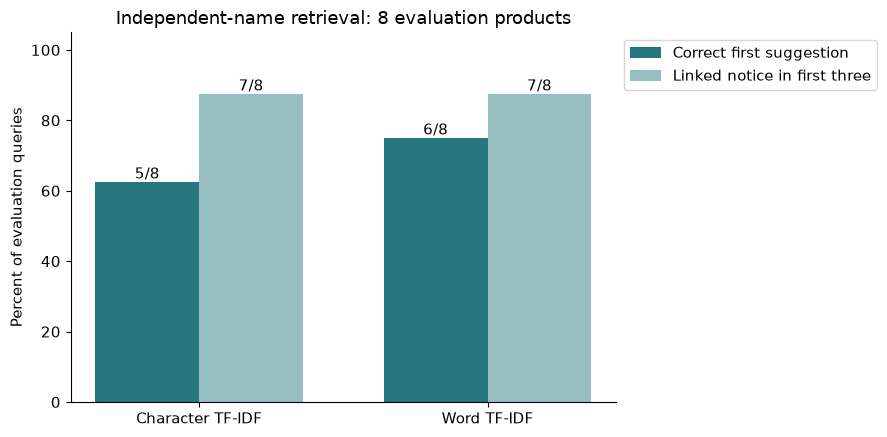

In [18]:
errors = retrieval_results.loc[~retrieval_results['top1_correct']].copy()
error_details = errors.merge(documents[['id', 'marque_produit', 'modeles_ou_references']],
                            left_on='top_notice', right_on='id', how='left', validate='many_to_one')
display(error_details[['split', 'method', 'query', 'score', 'expected_notices',
                       'top_notice', 'marque_produit', 'modeles_ou_references']].head(16))
print('All retrieval errors are retained in retrieval_results and in the exported results table.')
display(overlap.loc[overlap['gtin14'].eq('3327520004026'.zfill(14)),
                    ['code', 'product_name', 'brands', 'modeles_ou_references', 'numero_fiche']])
if not retrieval_metrics.empty:
    chart = retrieval_metrics.loc[retrieval_metrics['split'].eq('evaluation')]
    if not chart.empty:
        fig, ax = plt.subplots(figsize=(9, 4.5))
        positions = list(range(len(chart)))
        ax.bar([x - 0.18 for x in positions], chart['top1_percent'], width=0.36,
               label='Correct first suggestion', color='#267680')
        ax.bar([x + 0.18 for x in positions], chart['top3_percent'], width=0.36,
               label='Linked notice in first three', color='#98bec2')
        ax.set(xticks=positions, xticklabels=chart['method'], ylim=(0, 105),
               ylabel='Percent of evaluation queries',
               title=f'Independent-name retrieval: {int(chart.iloc[0]["queries"])} evaluation products')
        for x, (_, row) in zip(positions, chart.iterrows()):
            ax.text(x - 0.18, row['top1_percent'] + 1, f"{int(row['top1_correct'])}/{int(row['queries'])}", ha='center')
            ax.text(x + 0.18, row['top3_percent'] + 1, f"{round(row['top3_percent'] * row['queries'] / 100)}/{int(row['queries'])}", ha='center')
        ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
        fig.tight_layout()
        plt.show()

### A concrete failure: same family, different bottle and batch

Both methods suggest notice 3576 first for the independent Activilong query. Its title describes a 300 ml bottle and batch 28972. The barcode-linked notice 23142 describes a 250 ml bottle and batch 37019. The accepted barcodes in the two records differ. These comparisons come from the official downloaded recall records; the current 250 ml notice was also reviewed on the official website.

The catalogue stores the quantity separately from the name. Our name-only baseline does not use it. That is an explicit limitation, and a testable feature for the next phase. A high similarity score, even above 0.90, is not the probability that a recall applies.

**Useful next question:** Does adding package size and requiring an identity check reduce wrong-variant suggestions without hiding correct notices? Batch verification remains a separate task. We should test that on a new reviewed set rather than claim an improvement from this one example.

In [19]:
variant_notices = cosmetics.loc[cosmetics['id'].isin(['3576', '23142']), [
    'id', 'numero_fiche', 'modeles_ou_references', 'identification_produits', 'date_publication']]
display(variant_notices)
display(catalogue.loc[catalogue['gtin14'].eq('3327520004026'.zfill(14)),
                      ['code', 'product_name', 'quantity', 'brands', 'url']])
display(retrieval_results.loc[retrieval_results['gtin14'].eq('3327520004026'.zfill(14)),
                              ['method', 'score', 'top_notice', 'expected_notices', 'top3_notices']])
assert set(variant_notices['id']) == {'3576', '23142'}

,id,numero_fiche,modeles_ou_references,identification_produits,date_publication
384,23142,2026-08-0072,shampoing activateur de boucles 250ml activilong / acticurl lot 37019,"3327520004026,37019,non concerné",2026-08-14T11:01:54+00:00
15818,3576,2021-09-0279,activilong/ acticurl shampooing activateur de boucles 300 ml lot 28972,"3327520004439,28972,non concerné",2021-09-22T11:39:16+00:00


,code,product_name,quantity,brands,url
14605,3327520004026,ACTICURL HYDRA SHAMPOOING ACTIVATEUR DE BOUCLES,250 ml,ACTIVILONG,http://world-en.openbeautyfacts.org/product/3327520004026/acticurl-hydra-shampooing-activateur-de-boucles-...


,method,score,top_notice,expected_notices,top3_notices
5,Word TF-IDF,0.761966,3576,23142,"3576, 23142, 7374"
22,Character TF-IDF,0.906388,3576,23142,"3576, 23142, 8428"


## 20. Stress test: products without a barcode link

A text model always has a nearest result, even for a different product. We take up to 30 named catalogue products from the same brands as the overlapping products but whose GTIN is absent from our accepted recall index. They are **unlinked identities**, not certified unaffected products: some recalls have missing or unusable GTINs.

This demonstrates how easily forced ranking can produce unsupported suggestions. It cannot estimate clinical false-alert rates or market-wide precision. We show suggestions exceeding a fixed illustrative similarity threshold of 0.65. That threshold is not calibrated and must not decide consumer safety. A final benchmark needs original-notice review of these near-neighbour cases.

In [20]:
catalogue['brand_key'] = catalogue['brands'].fillna('').map(normalise_name)
overlap_brands = set(catalogue.loc[catalogue['gtin14'].isin(queries['gtin14']), 'brand_key']) - {''}
unlinked_pool = catalogue.loc[catalogue['has_name'] & catalogue['brand_key'].isin(overlap_brands) &
                             ~catalogue['gtin14'].isin(barcode_index['gtin14'])].copy()
stress_queries = unlinked_pool.sort_values('gtin14').sample(
    n=min(30, len(unlinked_pool)), random_state=42).sort_values('gtin14').copy()
stress_rows = []
if not stress_queries.empty and not queries.empty:
    stress_text = (stress_queries['brands'].fillna('') + ' ' +
                   stress_queries['product_name'].fillna('')).map(normalise_name)
    for method, vectorizer in methods.items():
        indexed = vectorizer.transform(document_text)
        similarities = (vectorizer.transform(stress_text) @ indexed.T).toarray()
        for i, (_, query) in enumerate(stress_queries.iterrows()):
            best = int(similarities[i].argmax())
            score = float(similarities[i, best])
            stress_rows.append({'gtin14': query['gtin14'], 'method': method,
                'catalogue_product': query['product_name'], 'catalogue_brand': query['brands'],
                'suggested_notice': documents.iloc[best]['id'],
                'suggested_product': documents.iloc[best]['modeles_ou_references'],
                'score': score, 'above_illustrative_threshold': score >= 0.65})
stress_results = pd.DataFrame(stress_rows)
if stress_results.empty:
    print('No eligible stress-test queries in this snapshot.')
else:
    display(stress_results.groupby('method').agg(
        unlinked_queries=('gtin14', 'size'),
        suggestions_above_065=('above_illustrative_threshold', 'sum')))
    display(stress_results.sort_values('score', ascending=False).head(10))
assert set(stress_queries['gtin14']).isdisjoint(set(barcode_index['gtin14']))

,unlinked_queries,suggestions_above_065
method,,
Character TF-IDF,30,1
Word TF-IDF,30,0


,gtin14,method,catalogue_product,catalogue_brand,suggested_notice,suggested_product,score,above_illustrative_threshold
58,08436097095605,Character TF-IDF,lait corporal,byphasse,8196,lait douche byphasse extraits de coton 500ml ¤apres-shampoing byphasse chev secs karité &miel 400ml,0.655186,True
59,08436097095889,Character TF-IDF,Lotion tonique,Byphasse,8196,lait douche byphasse extraits de coton 500ml ¤apres-shampoing byphasse chev secs karité &miel 400ml,0.544348,False
49,03327520004231,Character TF-IDF,sérum lissant argan,Activilong,23142,shampoing activateur de boucles 250ml activilong / acticurl lot 37019,0.513177,False
30,03245677725437,Character TF-IDF,Déodorant,Cosmia,9024,deodorant 150 ml,0.510175,False
57,08436097095544,Character TF-IDF,Purifying Cleansing Gel,Byphasse,8196,lait douche byphasse extraits de coton 500ml ¤apres-shampoing byphasse chev secs karité &miel 400ml,0.509826,False
47,03256226396534,Character TF-IDF,Délice de Vanille,U,14062,deodorant bille anti-transpirant au parfum vanille et a l'extrait de vanille 50ml ysiance,0.496668,False
44,03256222741178,Character TF-IDF,Dentifrice Blancheur,U,12107,poudre blancheur des dents 40 g,0.478260,False
39,03245678599235,Character TF-IDF,Crème visage et corps,Cosmia,9517,crème solaire visage et corps ind 25,0.476782,False
28,08436097095605,Word TF-IDF,lait corporal,byphasse,8196,lait douche byphasse extraits de coton 500ml ¤apres-shampoing byphasse chev secs karité &miel 400ml,0.467022,False
9,03245678599235,Word TF-IDF,Crème visage et corps,Cosmia,9517,crème solaire visage et corps ind 25,0.437979,False


## 21. Batch check: a narrow, reviewed example

The official Activilong notice describes a 250 ml curl-activating shampoo, batch **37019**, published on **14 August 2026** for France. The reason is a non-compliant microbiological control, with reported Pseudomonas aeruginosa contamination risk. It explains where the batch is printed and gives consumer instructions. [Original notice](https://rappel.conso.gouv.fr/static/fiches/fc56c943-13a9-46b8-a4b4-afc4eb9f3321.html).

The function below is deliberately limited to this reviewed notice. It checks the barcode and batch from the export, verifies the expected source reference, and returns one of three answers: listed batch, another batch not listed in this notice, or missing batch information. It never labels a product safe. It does not automatically apply this simple rule to complex notices or different countries.

The five cases are deterministic regression checks, not a user study or a population accuracy estimate. Product identity and batch applicability are separate checks.

In [21]:
reviewed_notice = cosmetics.loc[cosmetics['id'].eq('23142')]
if len(reviewed_notice) != 1:
    raise ValueError('Reviewed Activilong notice is missing or duplicated.')
reviewed_notice = reviewed_notice.iloc[0]
if reviewed_notice['numero_fiche'] != '2026-08-0072':
    raise ValueError('Reviewed notice reference changed; review the source again.')
if reviewed_notice['identification_produits'] != '3327520004026,37019,non concerné':
    raise ValueError('Reviewed batch information changed; review the source again.')

def check_reviewed_batch(barcode, batch):
    if not isinstance(barcode, str) or not valid_gtin(barcode.strip()):
        raise ValueError('Barcode must be a valid GTIN supplied as text.')
    if barcode.strip().zfill(14) != '3327520004026'.zfill(14):
        return 'No identity match to this reviewed notice'
    if batch is None or batch is pd.NA or (isinstance(batch, float) and pd.isna(batch)) or (isinstance(batch, str) and not batch.strip()):
        return 'Batch unknown: read the label and verify the official notice'
    if not isinstance(batch, str):
        raise TypeError('Batch must be supplied as text to preserve leading zeros.')
    if batch.strip() == '37019':
        return 'Product identity and listed batch match this French notice'
    return 'Batch not listed in this notice: no safety conclusion'

batch_cases = pd.DataFrame([
    ('Listed batch', '3327520004026', '37019',
     'Product identity and listed batch match this French notice'),
    ('Different batch', '3327520004026', '37020',
     'Batch not listed in this notice: no safety conclusion'),
    ('Missing batch', '3327520004026', None,
     'Batch unknown: read the label and verify the official notice'),
    ('Equivalent 14 digit GTIN', '03327520004026', '37019',
     'Product identity and listed batch match this French notice'),
    ('Different valid product identity', '4006381333931', '37019',
     'No identity match to this reviewed notice'),
], columns=['case', 'barcode', 'batch', 'expected'])
batch_cases['actual'] = batch_cases.apply(lambda row: check_reviewed_batch(row['barcode'], row['batch']), axis=1)
assert batch_cases['actual'].eq(batch_cases['expected']).all()
try:
    check_reviewed_batch('3327520004027', '37019')
except ValueError:
    pass
else:
    raise AssertionError('Invalid check digit was accepted.')
display(batch_cases[['case', 'barcode', 'batch', 'actual']])
display(reviewed_notice[['numero_fiche', 'informations_complementaires',
                         'conduites_a_tenir_par_le_consommateur',
                         'modalites_de_compensation', 'lien_vers_la_fiche_rappel']].to_frame('source_text'))

,case,barcode,batch,actual
0,Listed batch,3327520004026,37019,Product identity and listed batch match this French notice
1,Different batch,3327520004026,37020,Batch not listed in this notice: no safety conclusion
2,Missing batch,3327520004026,NaN,Batch unknown: read the label and verify the official notice
3,Equivalent 14 digit GTIN,03327520004026,37019,Product identity and listed batch match this French notice
4,Different valid product identity,4006381333931,37019,No identity match to this reviewed notice


,source_text
numero_fiche,2026-08-0072
informations_complementaires,le numéro de lot se situe au-dessus de l'adresse de la société en bas de l'étiquette.
conduites_a_tenir_par_le_consommateur,ne plus utiliser le produit|rapporter le produit au point de vente|contacter le service consommateur|détru...
modalites_de_compensation,remboursement
lien_vers_la_fiche_rappel,https://rappel.conso.gouv.fr/fiche-rappel/23142/interne


## 22. Feasibility decision and the next research gate

The result below is computed from this snapshot. Our minimum of 30 named overlapping identities is a practical checkpoint for a small internship benchmark, not a statistically justified sample size. Even if we pass it, that does not justify public release. The number of evaluation products and the error table determine how modest our claims must be.

In [22]:
evaluation_products = int(queries['split'].eq('evaluation').sum())
minimum_overlap = 30
decision = ('Proceed with a limited matching benchmark and source review'
            if len(queries) >= minimum_overlap else
            'Narrow to recall data quality and batch interpretation; seek more verified catalogue overlap')
display(Markdown(f"""
### Decision: {decision}

- We retained **{len(cosmetics)}** French cosmetic notices. **{len(matched_ids)}** have a barcode accepted by our conservative parser.
- The independent catalogue overlaps **{overlap_products}** product identities across **{overlap_notices}** notices. **{len(queries)}** identities have usable names for retrieval; **{evaluation_products}** are in the evaluation split.
- Both text baselines have measured results above. Barcode retrieval is the label-building reference, so reporting its accuracy on those same labels would be circular.
- Batch applicability has a reviewed demonstration for one notice, not a general validated parser.
- **Recommended contribution:** an auditable benchmark that shows where identity matching fails, retains batch conditions and declines to make unsupported safety claims. Train a semantic model only after source review confirms labels and exposes a meaningful baseline weakness.
- **Human outcome to measure later:** correct identification of affected batches and official next steps, plus time taken. No reduction in injuries or real-time detection has been established.
"""))

RESULTS_DIR = PROJECT_DIR / 'data/processed'
RESULTS_DIR.mkdir(exist_ok=True)
retrieval_results.to_csv(RESULTS_DIR / 'independent_name_retrieval.csv', index=False)
retrieval_metrics.to_csv(RESULTS_DIR / 'retrieval_metrics.csv', index=False)
if not stress_results.empty:
    stress_results.to_csv(RESULTS_DIR / 'unlinked_identity_stress_test.csv', index=False)
identifiers.to_csv(RESULTS_DIR / 'identifier_audit.csv', index=False)
print('Reproducible result tables:', RESULTS_DIR.relative_to(PROJECT_DIR))


### Decision: Narrow to recall data quality and batch interpretation; seek more verified catalogue overlap

- We retained **296** French cosmetic notices. **197** have a barcode accepted by our conservative parser.
- The independent catalogue overlaps **30** product identities across **22** notices. **17** identities have usable names for retrieval; **8** are in the evaluation split.
- Both text baselines have measured results above. Barcode retrieval is the label-building reference, so reporting its accuracy on those same labels would be circular.
- Batch applicability has a reviewed demonstration for one notice, not a general validated parser.
- **Recommended contribution:** an auditable benchmark that shows where identity matching fails, retains batch conditions and declines to make unsupported safety claims. Train a semantic model only after source review confirms labels and exposes a meaningful baseline weakness.
- **Human outcome to measure later:** correct identification of affected batches and official next steps, plus time taken. No reduction in injuries or real-time detection has been established.


Reproducible result tables: data/processed


## 23. What we need before a stronger claim

| Claim we want to make | Evidence required | Current position |
|---|---|---|
| We can retrieve the correct product notice | Independently reviewed product pairs, original notices and competing variants | Barcode-linked names provide a small provisional benchmark |
| AI is better than simple search | Fixed baselines, fresh held-out products, paired error comparison, precision at an agreed review workload | Two text baselines run; no semantic model superiority claimed |
| A recall applies to this batch | Original lot/date conditions, checked interpretation and reviewed positive/negative/unknown batch cases | One narrow notice reviewed |
| People understand the warning better | Participants correctly identify lot, market and next step; compare accuracy and time with existing notice | User study not performed |
| Retailers save time | Real or consented inventory task, manual-review baseline, time and correct decisions | No retailer workflow measured |
| The service is real-time | Refresh schedule, change detection, withdrawal/version tracking, measured publication-to-ingestion delay | Downloaded snapshots only |
| Results apply to India | Indian notices or verified local products, batches, formulations and jurisdiction review | Not established by French or UK data |

**Week 1 boundary:** Define and justify the problem using these feasibility findings. Weeks 2 to 6 build on the same problem with separate reports. Do not invent six unrelated projects.

**Next concrete step:** Review the overlapping product pairs and the highest-scoring unlinked suggestions against their original notices. Build labels of identity match, different variant and unresolved. Preserve unknown batch status. Then decide whether semantic retrieval is worth comparing with the measured baselines.

## 24. Refined Week 1 problem and hypotheses

**Problem:** Consumers and retailers need to identify applicable cosmetic recalls despite inconsistent product names, compound identifier fields and incomplete guidance.

**Decision:** Does a notice appear to apply to this exact product and batch, and what does the official notice advise?

**Initial scope:** Published French cosmetic recalls, with UK aggregate statistics used for context. An Indian application would require checking local products, formulations, batches and regulations.

**Research questions and hypotheses to evaluate later:**

1. Does adding barcode information improve matching over product names alone? Hypothesis: exact validated barcode matches improve precision when barcodes are available. Test with independently reviewed matching and non-matching examples.
2. Can AI help retrieve notices when a product name is written differently? Hypothesis: text similarity improves recall over literal name matching. Compare a simple text baseline with a semantic model on held-out products, including similar names and different variants.
3. Can plain-language explanations help a reader identify the affected batch and correct next step? Hypothesis: readers answer these questions more accurately with the explanation. This needs a small user study; the downloaded datasets alone cannot establish it.

**Validation:** Review original notices, measure precision and recall, examine false warnings and missed matches, and keep variants of the same product out of both training and test sets. Artificial spelling variations can help development but cannot substitute for real independent test examples.

**Updated feasibility:** Open Beauty Facts provides independently written product names and barcode overlap. The measured coverage, retrieval errors and limitations appear in Sections 15 to 22. Barcode joins are provisional labels; final matching and non-matching examples still need original-notice review. Absence from the recall dataset is not a safe-product label.

## 25. Bias, errors and limits to handle

| Issue | What we will do | What remains uncertain |
|---|---|---|
| Enforcement and reporting bias | Describe notices and source coverage; avoid market-wide hazard rates | How many products were tested or sold |
| Updated notices | Retain IDs and versions; inspect repeated references before counting | Whether later downloads revise earlier records |
| Incomplete dates | Flag failures; use only valid dates for time charts | Dates of actual exposure or harm |
| Compound barcode and batch fields | Preserve original text; validate parser output against notices | Whether every usable identifier is captured |
| Similar names, variants and batches | Return candidate matches; require batch verification | Applicability when the user cannot identify the lot |
| Missing instructions | Show missing information and the official link | Guidance omitted from the export |
| French text | Use an explicit glossary for labels; verify any future translation | Whether translations preserve every condition |
| AI mistakes | Compare with simple methods; audit false matches and missed notices | Generalisation to products absent from the test set |
| Source update delay | Show snapshot date; later measure refresh delay | Actual delay from hazard discovery to publication |

If code raises an error, read the message and review the source structure. We do not replace required missing data with zero, suppress parsing errors, or silently remove difficult notices.

## 26. Six week plan

| Week | Work and deliverable |
|---|---|
| 1 | Define the problem, stakeholders, questions, hypotheses and feasibility in a Word report |
| 2 | Audit recall sources and an independent product catalogue; document access, coverage and matching labels |
| 3 | Build and document cleaning, version handling, barcode extraction and batch preservation |
| 4 | Explore hazards and coverage; engineer product-name and identity features |
| 5 | Compare exact/text matching baselines with a suitable AI retrieval model, if verified examples are sufficient |
| 6 | Evaluate matches and explanations; present a prototype, error analysis and business recommendations |

Submission folders are organised under `submissions/week_01` through `week_06`. Reports will be drafted from verified work as each week progresses.

## 27. STAR summary

**Situation:** Cosmetic recall notices identify affected products and sometimes particular batches. Consumers and retailers can confuse similar names or treat a matching barcode as confirmation that every batch is affected. Existing scanning services already address parts of this task.

**Task:** Determine whether free public data can support a useful, transparent product-and-batch matching study for the six week internship.

**Action:** Audit French notices and UK context separately, preserve missing values, validate GTINs, download an independent product catalogue, measure barcode overlap, compare two text retrieval baselines, expose retrieval errors and unsupported near-neighbour suggestions, and check one source-reviewed batch example with runnable assertions.

**Result:** The computed coverage and performance tables define what is feasible and where matching remains uncertain. The project has a concrete benchmark and error-analysis contribution. A general batch parser, improved user decisions, superiority over existing tools, real-time operation and reduced harm have not been established. Proceed according to the feasibility decision in Section 22.